<a href="https://colab.research.google.com/github/Ayeshaismail5/plant-disease-detection/blob/part1-data-cnn/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, sys, shutil
import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    SHARED     = "/content/drive/MyDrive/PlantDisease_Shared"
    SRC_BASE   = f"{SHARED}/PlantVillage"          # read-only dataset on Drive
    LOCAL_BASE = "/content/data/PlantVillage"       # fast local copy used for scanning
    WORK       = f"{SHARED}/part1_work"             # your outputs (kept on Drive)
else:
    SRC_BASE   = os.environ.get("PV_SRC", "../data/raw/PlantVillage")
    LOCAL_BASE = SRC_BASE
    WORK       = ".."                               # the ml/ folder

SRC_DIR, REPORTS_DIR, SAVED_DIR = f"{WORK}/src", f"{WORK}/reports", f"{WORK}/saved_models"
FIG_DIR = f"{REPORTS_DIR}/figures"
for d in (SRC_DIR, REPORTS_DIR, SAVED_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

assert os.path.exists(f"{SRC_DIR}/data_utils.py"), f"Upload data_utils.py to {SRC_DIR}"
sys.path.insert(0, SRC_DIR)
import data_utils as du

SEED = 42
print("Colab:", IN_COLAB, "| source:", SRC_BASE, "| work:", WORK)

Mounted at /content/drive
Colab: True | source: /content/drive/MyDrive/PlantDisease_Shared/PlantVillage | work: /content/drive/MyDrive/PlantDisease_Shared/part1_work


## Step 0 - Copy dataset to local disk (Colab only)
Reading thousands of small files from Drive is slow. This runs once per session and can take several minutes.

In [ ]:
if IN_COLAB and not os.path.exists(LOCAL_BASE):
    shutil.copytree(SRC_BASE, LOCAL_BASE)
print("Local copy exists:", os.path.exists(LOCAL_BASE))

Local copy exists: True


## Step 1 - Real directory structure (look for nested or duplicated folders)

In [ ]:
du.print_tree(LOCAL_BASE, max_depth=3)
CLASS_ROOT = du.find_class_root(LOCAL_BASE)
print("\nDetected class root:", CLASS_ROOT)
assert CLASS_ROOT is not None, "No folder with >=2 image sub-folders found. Check the tree above."

PlantVillage/  subfolders=16  files=0
  Pepper__bell___Bacterial_spot/  subfolders=0  files=997
  Pepper__bell___healthy/  subfolders=0  files=1478
  PlantVillage/  subfolders=15  files=0
    Pepper__bell___Bacterial_spot/  subfolders=0  files=997
    Pepper__bell___healthy/  subfolders=0  files=1478
    Potato___Early_blight/  subfolders=0  files=1000
    Potato___Late_blight/  subfolders=0  files=1000
    Potato___healthy/  subfolders=0  files=152
    Tomato_Bacterial_spot/  subfolders=0  files=2127
    Tomato_Early_blight/  subfolders=0  files=1000
    Tomato_Late_blight/  subfolders=0  files=1909
    Tomato_Leaf_Mold/  subfolders=0  files=952
    Tomato_Septoria_leaf_spot/  subfolders=0  files=1771
    Tomato_Spider_mites_Two_spotted_spider_mite/  subfolders=0  files=1676
    Tomato__Target_Spot/  subfolders=0  files=1404
    Tomato__Tomato_YellowLeaf__Curl_Virus/  subfolders=0  files=3209
    Tomato__Tomato_mosaic_virus/  subfolders=0  files=373
    Tomato_healthy/  subfolders=0  

## Step 2 - Raw class names first, then the plant/disease parse
Check the parse table by eye. If a plant or disease is split wrongly, tell me before Phase 2.

In [ ]:
class_names, skipped = du.list_class_dirs(CLASS_ROOT)
print("Number of class folders:", len(class_names))
print("Folders WITHOUT images (skipped):", skipped)
for i, c in enumerate(class_names):
    print(f"{i:>2}  {c}")

Number of class folders: 15
Folders WITHOUT images (skipped): ['PlantVillage']
 0  Pepper__bell___Bacterial_spot
 1  Pepper__bell___healthy
 2  Potato___Early_blight
 3  Potato___Late_blight
 4  Potato___healthy
 5  Tomato_Bacterial_spot
 6  Tomato_Early_blight
 7  Tomato_Late_blight
 8  Tomato_Leaf_Mold
 9  Tomato_Septoria_leaf_spot
10  Tomato_Spider_mites_Two_spotted_spider_mite
11  Tomato__Target_Spot
12  Tomato__Tomato_YellowLeaf__Curl_Virus
13  Tomato__Tomato_mosaic_virus
14  Tomato_healthy


In [ ]:
parsed = [du.parse_class_name(c) for c in class_names]
parsed_df = pd.DataFrame(parsed)
display(parsed_df)
print("Plants found:", sorted(parsed_df["plant"].unique()))

,raw,plant,disease,is_healthy
0,Pepper__bell___Bacterial_spot,Pepper,Bacterial spot,False
1,Pepper__bell___healthy,Pepper,healthy,True
2,Potato___Early_blight,Potato,Early blight,False
3,Potato___Late_blight,Potato,Late blight,False
4,Potato___healthy,Potato,healthy,True
5,Tomato_Bacterial_spot,Tomato,Bacterial spot,False
6,Tomato_Early_blight,Tomato,Early blight,False
7,Tomato_Late_blight,Tomato,Late blight,False
8,Tomato_Leaf_Mold,Tomato,Leaf Mold,False
9,Tomato_Septoria_leaf_spot,Tomato,Septoria leaf spot,False


Plants found: ['Pepper', 'Potato', 'Tomato']


## Steps 3-4 - Scan every file (verify, reopen, mode, size, MD5)
Saved to `file_inventory.csv`, so a Colab disconnect does not force a rescan. Set `FORCE_RESCAN = True` to redo it.

In [ ]:
FORCE_RESCAN = False
inv_path, other_path = f"{REPORTS_DIR}/file_inventory.csv", f"{REPORTS_DIR}/non_image_files.csv"
if os.path.exists(inv_path) and not FORCE_RESCAN:
    df = pd.read_csv(inv_path)
    other_df = pd.read_csv(other_path) if os.path.exists(other_path) else pd.DataFrame(columns=["class","filepath","ext"])
    print("Loaded existing inventory:", len(df), "image files")
else:
    df, other_df = du.scan_dataset(CLASS_ROOT, class_names, workers=8)
    df.to_csv(inv_path, index=False); other_df.to_csv(other_path, index=False)
    print("Scanned:", len(df), "image files")

Scanning images:   0%|          | 0/20638 [00:00<?, ?it/s]

Scanned: 20638 image files


## Step 3 - Counts per class and per plant, distribution plot, imbalance ratio

,class,n_files,n_valid,plant
0,Tomato__Tomato_YellowLeaf__Curl_Virus,3208,3208,Tomato
1,Tomato_Bacterial_spot,2127,2127,Tomato
2,Tomato_Late_blight,1909,1909,Tomato
3,Tomato_Septoria_leaf_spot,1771,1771,Tomato
4,Tomato_Spider_mites_Two_spotted_spider_mite,1676,1676,Tomato
5,Tomato_healthy,1591,1591,Tomato
6,Pepper__bell___healthy,1478,1478,Pepper
7,Tomato__Target_Spot,1404,1404,Tomato
8,Potato___Early_blight,1000,1000,Potato
9,Potato___Late_blight,1000,1000,Potato



Images per plant:
 plant
Tomato    16011
Pepper     2475
Potato     2152
Name: n_valid, dtype: int64

Imbalance ratio (max/min): 21.11


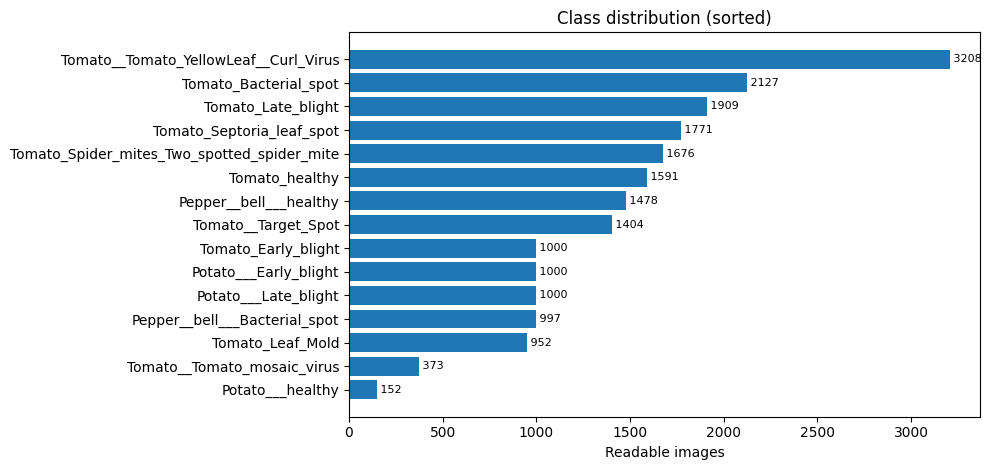

In [ ]:
counts = du.class_counts(df, parsed)
display(counts)
print("\nImages per plant:\n", counts.groupby("plant")["n_valid"].sum().sort_values(ascending=False))
print("\nImbalance ratio (max/min):", round(du.imbalance_ratio(counts), 2))
du.plot_class_distribution(counts, out_path=f"{FIG_DIR}/class_distribution.png")

## Step 4 - File integrity: corrupted, non-RGB, size and format variation

In [ ]:
corrupt = df[df["status"] == "corrupt"]
print("Corrupted / unreadable files:", len(corrupt))
display(corrupt[["class", "filepath", "error"]].head(50))

ok = df[df["status"] == "ok"].astype({"width": int, "height": int})
print("\nFile extensions:\n", df["ext"].value_counts())
print("\nPIL formats:\n", ok["format"].value_counts())
print("\nColour modes:\n", ok["mode"].value_counts())
print("Non-RGB images:", int((ok["mode"] != "RGB").sum()))
sizes = ok.groupby(["width", "height"]).size().sort_values(ascending=False)
print("\nDistinct image sizes:", len(sizes)); print(sizes.head(10))
print("\nNon-image files found inside class folders:", len(other_df))
if len(other_df): print(other_df["ext"].value_counts())

Corrupted / unreadable files: 0


,class,filepath,error



File extensions:
 ext
.jpg     20636
.png         1
.jpeg        1
Name: count, dtype: int64

PIL formats:
 format
JPEG    20637
PNG         1
Name: count, dtype: int64

Colour modes:
 mode
RGB     20637
RGBA        1
Name: count, dtype: int64
Non-RGB images: 1

Distinct image sizes: 1
width  height
256    256       20638
dtype: int64

Non-image files found inside class folders: 1
ext
    1
Name: count, dtype: int64


## Step 5 - Exact duplicates (MD5), across the whole dataset

In [ ]:
dup_df, dup_summary = du.find_exact_duplicates(df)
print(dup_summary)
if len(dup_df):
    print("\nGroups that span MORE THAN ONE class (label conflicts):")
    display(dup_df[dup_df["n_classes"] > 1].head(30))
    print("\nSample of within-class duplicate groups:")
    display(dup_df[dup_df["n_classes"] == 1].head(30)[["md5", "class", "filepath", "n"]])

{'n_duplicate_groups': 14, 'n_files_in_duplicate_groups': 28, 'n_redundant_copies': 14, 'groups_within_one_class': 14, 'groups_across_classes': 0}

Groups that span MORE THAN ONE class (label conflicts):


,class,filepath,size_bytes,md5,status,error,width,height,mode,format,ext,n,n_classes



Sample of within-class duplicate groups:


,md5,class,filepath,n
9119,0e0dcd876f5b32cac9da836b2e783d91,Tomato_Late_blight,/content/data/PlantVillage/Tomato_Late_blight/...,2
8998,0e0dcd876f5b32cac9da836b2e783d91,Tomato_Late_blight,/content/data/PlantVillage/Tomato_Late_blight/...,2
9450,1d87a50fa691cef6f476b20bb48cfaf8,Tomato_Late_blight,/content/data/PlantVillage/Tomato_Late_blight/...,2
9247,1d87a50fa691cef6f476b20bb48cfaf8,Tomato_Late_blight,/content/data/PlantVillage/Tomato_Late_blight/...,2
20041,2e53ad1ec3f810e2ff4c83400dc69ec9,Tomato_healthy,/content/data/PlantVillage/Tomato_healthy/3720...,2
20106,2e53ad1ec3f810e2ff4c83400dc69ec9,Tomato_healthy,/content/data/PlantVillage/Tomato_healthy/5054...,2
20512,32cb22521edc69a5503a6749446dd522,Tomato_healthy,/content/data/PlantVillage/Tomato_healthy/068e...,2
20287,32cb22521edc69a5503a6749446dd522,Tomato_healthy,/content/data/PlantVillage/Tomato_healthy/34c8...,2
7860,3b227920ba50ce0a4602b258f624e935,Tomato_Late_blight,/content/data/PlantVillage/Tomato_Late_blight/...,2
9139,3b227920ba50ce0a4602b258f624e935,Tomato_Late_blight,/content/data/PlantVillage/Tomato_Late_blight/...,2


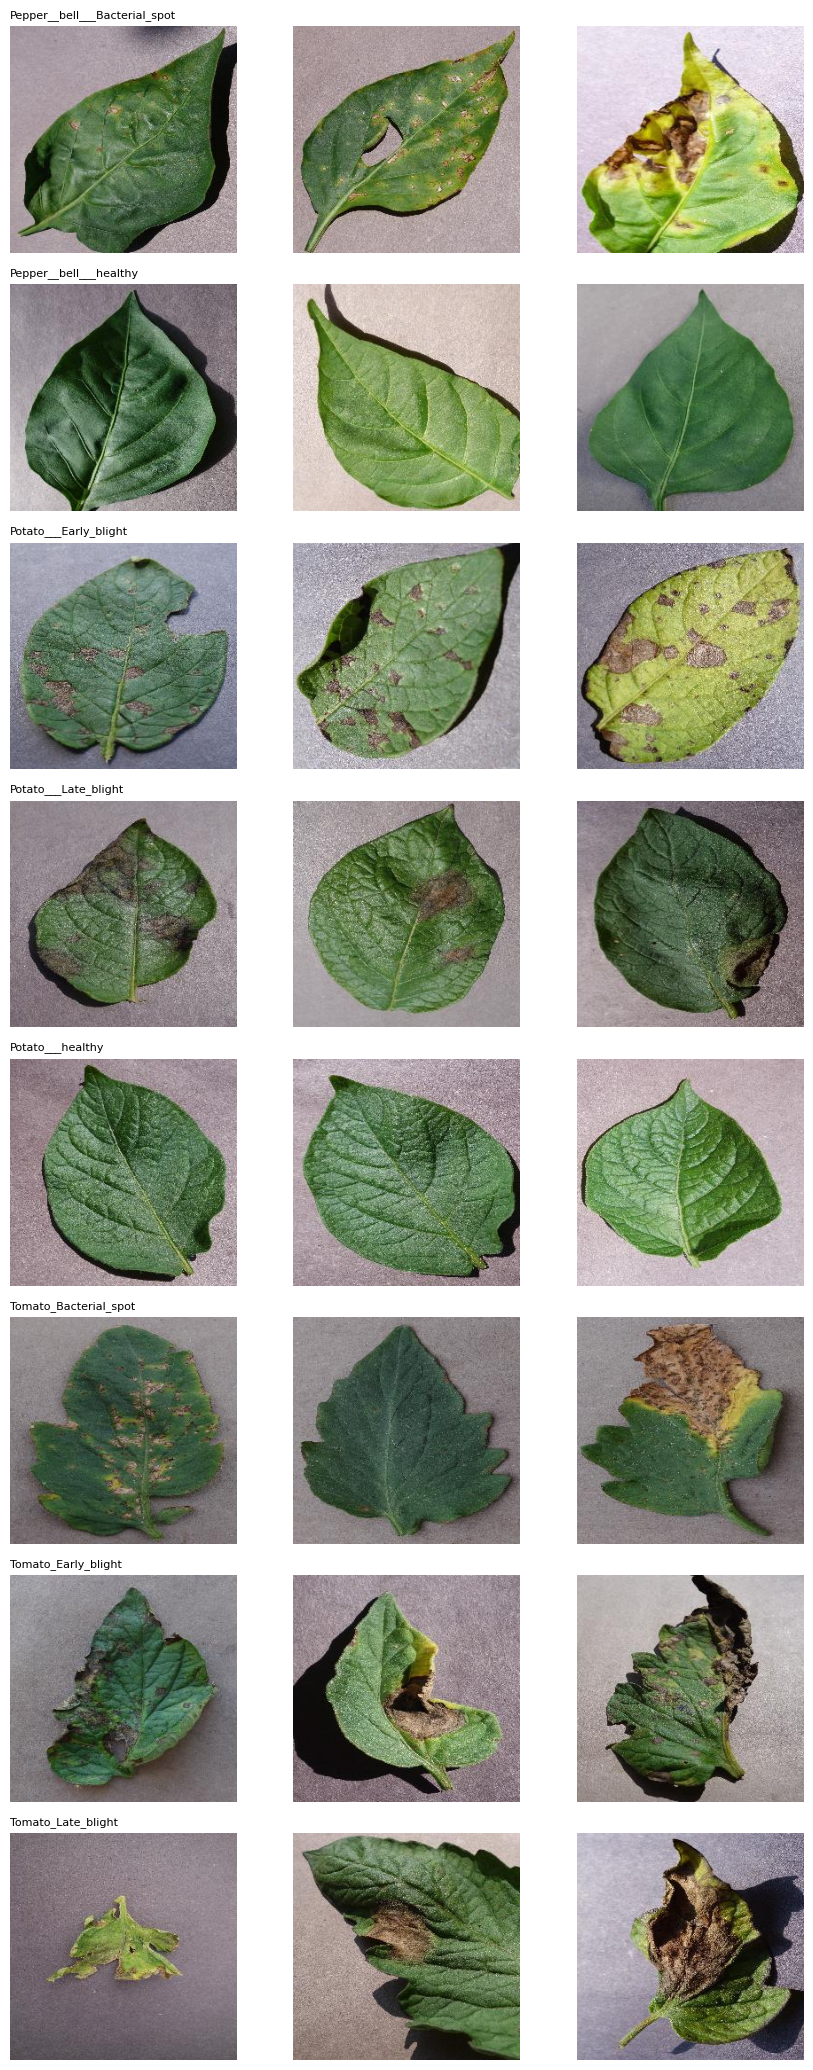

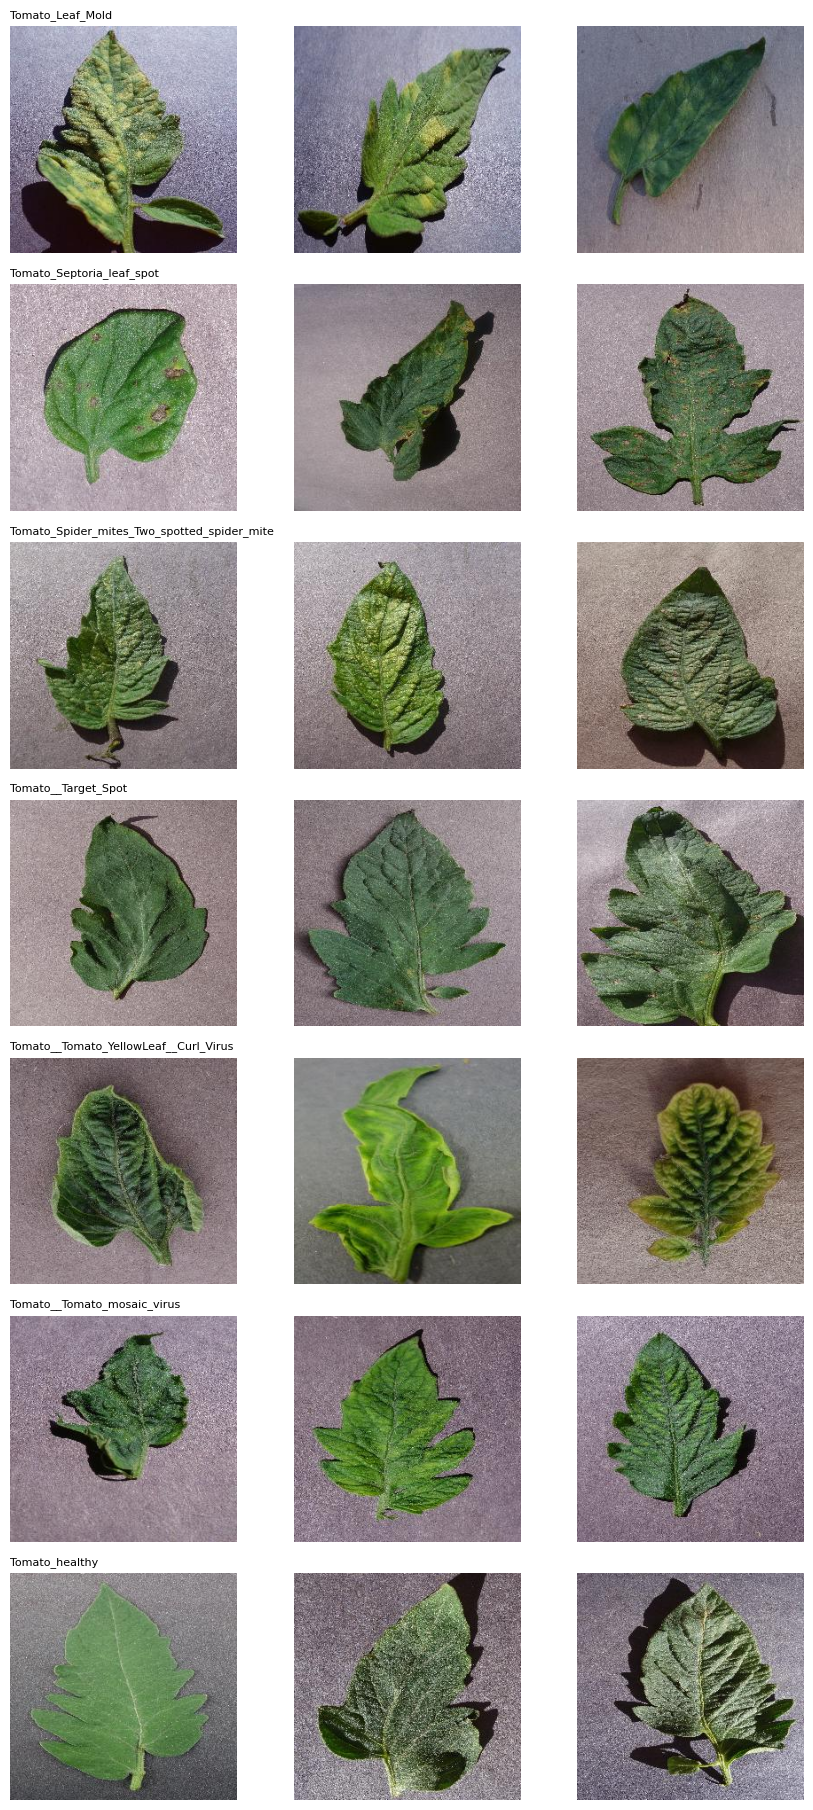

In [ ]:
du.show_sample_grid(df, per_class=3, seed=SEED, classes_per_figure=8, out_dir=FIG_DIR)

In [ ]:
du.save_json(class_names, f"{SAVED_DIR}/class_names.json")
summary = du.build_summary(LOCAL_BASE, CLASS_ROOT, class_names, parsed, df, other_df, counts, dup_summary)
du.save_json(summary, f"{REPORTS_DIR}/eda_summary.json")
print("Saved:", f"{SAVED_DIR}/class_names.json", "and", f"{REPORTS_DIR}/eda_summary.json")
print("\nSummary headline:")
for k in ["n_classes", "n_plants", "n_image_files", "n_readable", "n_corrupt", "n_non_rgb",
          "n_distinct_sizes", "imbalance_ratio_max_over_min", "max_class", "min_class", "exact_duplicates"]:
    print(f"  {k}: {summary[k]}")

Saved: /content/drive/MyDrive/PlantDisease_Shared/part1_work/saved_models/class_names.json and /content/drive/MyDrive/PlantDisease_Shared/part1_work/reports/eda_summary.json

Summary headline:
  n_classes: 15
  n_plants: 3
  n_image_files: 20638
  n_readable: 20638
  n_corrupt: 0
  n_non_rgb: 1
  n_distinct_sizes: 1
  imbalance_ratio_max_over_min: 21.105
  max_class: {'name': 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'n': 3208}
  min_class: {'name': 'Potato___healthy', 'n': 152}
  exact_duplicates: {'n_duplicate_groups': 14, 'n_files_in_duplicate_groups': 28, 'n_redundant_copies': 14, 'groups_within_one_class': 14, 'groups_across_classes': 0}


In [ ]:
# 1) Is the nested PlantVillage/ folder an exact copy (names + sizes)?
outer, inner = LOCAL_BASE, f"{LOCAL_BASE}/PlantVillage"
same = True
for c in class_names:
    a = {f: os.path.getsize(f"{outer}/{c}/{f}") for f in os.listdir(f"{outer}/{c}")}
    b = {f: os.path.getsize(f"{inner}/{c}/{f}") for f in os.listdir(f"{inner}/{c}")}
    if a != b:
        same = False
        print("DIFFERENT:", c, len(a), len(b), len(set(a) ^ set(b)))
print("Nested copy identical (names and sizes):", same)

# 2) The non-image file and the non-RGB image
display(other_df)
display(df[df["mode"] != "RGB"][["class", "filepath", "format", "mode"]])

# 3) Filename patterns
for c in class_names[:5]:
    print(c, [os.path.basename(p) for p in df[df["class"] == c]["filepath"].head(4)])

Nested copy identical (names and sizes): True


,class,filepath,ext
0,Tomato__Tomato_YellowLeaf__Curl_Virus,/content/data/PlantVillage/Tomato__Tomato_Yell...,


,class,filepath,format,mode
2455,Pepper__bell___healthy,/content/data/PlantVillage/Pepper__bell___heal...,PNG,RGBA


Pepper__bell___Bacterial_spot ['9029703b-db1b-4227-bd29-ab05cc53b7ba___NREC_B.Spot 1802.JPG', 'bdb598d7-7b7a-45cb-921a-f37cf7105006___NREC_B.Spot 1908.JPG', 'ef02f719-ca79-481f-9429-365fa1685a80___JR_B.Spot 9056.JPG', 'b7ec200a-5db5-479e-99d0-c40009123835___JR_B.Spot 3128.JPG']
Pepper__bell___healthy ['9d5afa2f-31ed-4f5b-aba4-f1f9725f97ef___JR_HL 7655.JPG', '6a6a7f87-4efb-43c7-ae36-1f9db31246f2___JR_HL 7703.JPG', '4d420109-050f-4d2a-a0c6-8f2bec2fe381___JR_HL 5951.JPG', '0ba474dd-0cfd-4fd2-a58c-8e3d18dbe7c3___JR_HL 8395.JPG']
Potato___Early_blight ['306c45ac-6f97-4b7e-9fad-1c8c39870138___RS_Early.B 7673.JPG', 'cfa37804-6d71-45fe-bd88-c899b9534992___RS_Early.B 6673.JPG', 'cbd4ef4a-1e84-41ac-8744-b5a1c52461be___RS_Early.B 8191.JPG', '6269c9ec-ef8a-49b5-ab1a-451565529c38___RS_Early.B 7166.JPG']
Potato___Late_blight ['fdb7d904-91df-4f00-85bd-0fb038723329___RS_LB 2628.JPG', '841a4e5a-7aa6-4b32-a2b2-436874a48fdb___RS_LB 4469.JPG', '5fa21fbf-774d-48ec-916d-c1d7b8c11c82___RS_LB 4795.JPG', '1757

In [ ]:
import re
from PIL import Image

# 1) The extensionless file(s) and the RGBA image
for p in other_df["filepath"]:
    print("OTHER:", p, os.path.getsize(p), "bytes")
    try:
        with Image.open(p) as im:
            print("  opens as image:", im.format, im.size, im.mode)
    except Exception as e:
        print("  not an image:", type(e).__name__, e)

for p in df[df["mode"] != "RGB"]["filepath"]:
    with Image.open(p) as im:
        print("RGBA file:", p, "| alpha min/max:", im.getchannel("A").getextrema())

# 2) Filename source code vs class
pat = re.compile(r'^[0-9a-f-]{36}___(?P<code>.+?)\s*(?P<num>\d+)\.(?:jpg|jpeg|png)$', re.I)
def parse_name(p):
    m = pat.match(os.path.basename(p))
    return (m["code"], int(m["num"])) if m else (None, None)

df[["code", "num"]] = df["filepath"].apply(lambda p: pd.Series(parse_name(p)))
print("Unparsed filenames:", df["code"].isna().sum())
df["site"] = df["code"].str.split("_").str[0]
display(pd.crosstab(df["class"], df["site"]))

OTHER: /content/data/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/svn-r6Yb5c 0 bytes
  not an image: UnidentifiedImageError cannot identify image file '/content/data/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/svn-r6Yb5c'
RGBA file: /content/data/PlantVillage/Pepper__bell___healthy/42f083e2-272d-4f83-ad9a-573ee90e50ec___Screen Shot 2015-05-06 at 4.01.13 PM.png | alpha min/max: (255, 255)
Unparsed filenames: 7


site,CG,Com.G,Crnl,GCREC,GH,GHLB,GHLB Leaf 1 Day,GHLB Leaf 1.1 Day,GHLB Leaf 1.2 Day,GHLB Leaf 1.4 Day,...,GHLB2ES Leaf 69.,JR,Keller.St,Matt.S,NREC,PSU,RS,UF.GRC,YLCV,bell-pepper-plant-
class,,,,,,,,,,,,,,,,,,,,,
Pepper__bell___Bacterial_spot,0,0,0,0,0,0,0,0,0,0,...,0,589,0,0,408,0,0,0,0,0
Pepper__bell___healthy,0,0,0,0,0,0,0,0,0,0,...,0,1476,0,0,0,0,0,0,0,1
Potato___Early_blight,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1000,0,0,0
Potato___Late_blight,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1000,0,0,0
Potato___healthy,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,152,0,0,0
Tomato_Bacterial_spot,0,0,0,1756,0,0,0,0,0,0,...,0,0,0,0,0,0,0,371,0,0
Tomato_Early_blight,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1000,0,0,0
Tomato_Late_blight,0,0,0,0,2,147,3,2,2,1,...,2,0,0,0,0,0,920,0,0,0
Tomato_Leaf_Mold,0,0,952,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Cleaner source code: first token of the filename code
df["site"] = df["code"].str.split(r"[_ ]", regex=True).str[0]
print("Distinct sources:", df["site"].nunique())
print("Unparsed filenames:")
print(df[df["code"].isna()]["filepath"].apply(os.path.basename).tolist())

ok = df[df["status"] == "ok"].dropna(subset=["site"])
ct = pd.crosstab(ok["site"], ok["class"])
for s in ct.sum(axis=1).sort_values(ascending=False).index:
    row = ct.loc[s]
    print(s, row[row > 0].to_dict())

baseline_acc = ct.max(axis=1).sum() / ct.values.sum()
print(f"\nSource-only majority baseline accuracy: {baseline_acc:.3f}")

Distinct sources: 17
Unparsed filenames:
['42f083e2-272d-4f83-ad9a-573ee90e50ec___Screen Shot 2015-05-06 at 4.01.13 PM.png', '1f38a263-cfb5-47fe-8c0e-f8d62141f922___GHLB_PS leaf 28 Day 12 .jpg', '784f6313-1080-4bd1-a556-d4e14e6879d0___GHLB_PS Leaf 53.1 Day 18 .jpg', 'c9f19d2a-8c9d-4ac1-b077-545c5d6f53a9___GHLB_PS Leaf 53 Day 18 .jpg', 'd45e9f86-2819-4c41-886c-73b7012674b3___GHLB Leaf 2 Day 16 .JPG', '7de93009-6180-4027-8779-76947cda3e2f___2700323949_95aa2eaa01_o.jpg', '0f5a5880-c1f1-4356-8336-d65c69b54cc1___GH_HL Leaf 380.1JPG.JPG']
RS {'Potato___Early_blight': 1000, 'Potato___Late_blight': 1000, 'Potato___healthy': 152, 'Tomato_Early_blight': 1000, 'Tomato_Late_blight': 920, 'Tomato_healthy': 999}
Com.G {'Tomato_Spider_mites_Two_spotted_spider_mite': 1676, 'Tomato__Target_Spot': 1404}
JR {'Pepper__bell___Bacterial_spot': 589, 'Pepper__bell___healthy': 1476, 'Tomato_Septoria_leaf_spot': 497}
UF.GRC {'Tomato_Bacterial_spot': 371, 'Tomato__Tomato_YellowLeaf__Curl_Virus': 1571}
GCREC {'To

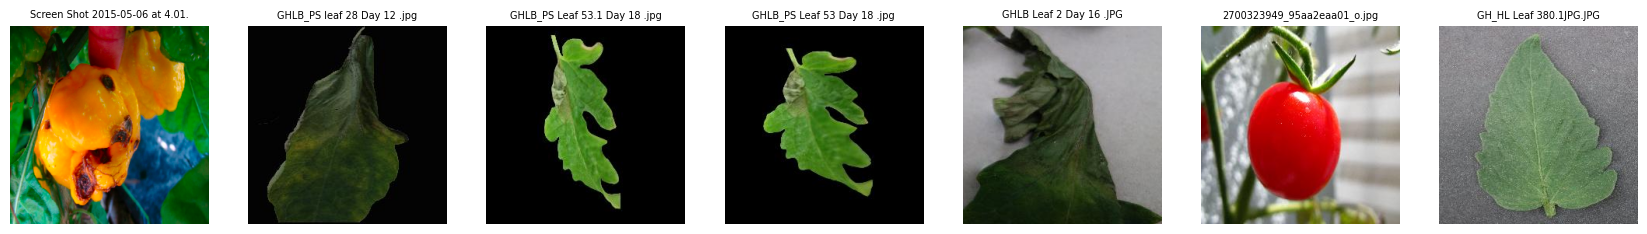

In [ ]:
from PIL import Image
odd = df[df["code"].isna()]["filepath"].tolist()
fig, axes = plt.subplots(1, len(odd), figsize=(3 * len(odd), 3.4))
for ax, p in zip(axes, odd):
    with Image.open(p) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(os.path.basename(p)[39:70], fontsize=7)
    ax.axis("off")
plt.show()

In [ ]:
import json, shutil

src = f"{SAVED_DIR}/class_names.json"
names = json.load(open(src))
print(len(names), "classes")
print(names)
assert len(names) == 15 and "PlantVillage" not in names

dst_dir = f"{SHARED}/1_dataset"
os.makedirs(dst_dir, exist_ok=True)
shutil.copy(src, f"{dst_dir}/class_names.json")
print(os.listdir(dst_dir))


15 classes
['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
['class_names.json']
